# Module 6 Lab 3: Retrieve, Search and Chart

**Name:** _Roey Kadur_  
**Repo URL:** _https://github.com/roee0910/cs82a-portfolio.git_  


## Step 1: Rebuild the customers table

This notebook rebuilds the Lab 2 table first, so it runs standalone from top to bottom.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("lab3.db")
con.execute("DROP TABLE IF EXISTS customers")   # lets the notebook be re-run from the top
con.execute("""
CREATE TABLE customers (
    id          INTEGER PRIMARY KEY,
    name        TEXT NOT NULL,
    city        TEXT,
    total_spent REAL
)
""")
con.execute("""
INSERT INTO customers (id, name, city, total_spent) VALUES
    (1,  'Maya Cohen',    'Tel Aviv',    1250.50),
    (2,  'Daniel Levi',   'Haifa',        830.00),
    (3,  'Noa Mizrahi',   'Jerusalem',   2145.75),
    (4,  'Yossi Katz',    'Tel Aviv',     415.20),
    (5,  'Tamar Peretz',  'Haifa',       1980.00),
    (6,  'Omer Biton',    'Beer Sheva',   260.90),
    (7,  'Shira Dahan',   'Jerusalem',    999.99),
    (8,  'Eitan Azulay',  'Tel Aviv',    3050.00),
    (9,  'Lior Friedman', 'Eilat',        120.00),
    (10, 'Hila Golan',    'Beer Sheva',   742.35)
""")
con.commit()
print("Rows in customers:", con.execute("SELECT COUNT(*) FROM customers").fetchone()[0])

Rows in customers: 10


In [2]:
pd.read_sql("SELECT * FROM customers", con)

,id,name,city,total_spent
0,1,Maya Cohen,Tel Aviv,1250.50
1,2,Daniel Levi,Haifa,830.00
2,3,Noa Mizrahi,Jerusalem,2145.75
3,4,Yossi Katz,Tel Aviv,415.20
4,5,Tamar Peretz,Haifa,1980.00
5,6,Omer Biton,Beer Sheva,260.90
6,7,Shira Dahan,Jerusalem,999.99
7,8,Eitan Azulay,Tel Aviv,3050.00
8,9,Lior Friedman,Eilat,120.00
9,10,Hila Golan,Beer Sheva,742.35


## Query 1: Filter with WHERE

Only the customers who spent more than 1000 USD. (Conditions can be combined with AND or OR, for example by adding a city.)

In [3]:
big_spenders = pd.read_sql("""
    SELECT id, name, city, total_spent
    FROM customers
    WHERE total_spent > 1000
""", con)
print(len(big_spenders), "customers spent more than 1000")
big_spenders

4 customers spent more than 1000


,id,name,city,total_spent
0,1,Maya Cohen,Tel Aviv,1250.50
1,3,Noa Mizrahi,Jerusalem,2145.75
2,5,Tamar Peretz,Haifa,1980.00
3,8,Eitan Azulay,Tel Aviv,3050.00


## Query 2: Sort with ORDER BY

The five highest-spending customers, biggest first. `LIMIT 5` caps the result.

In [4]:
pd.read_sql("""
    SELECT name, city, total_spent
    FROM customers
    ORDER BY total_spent DESC
    LIMIT 5
""", con)

,name,city,total_spent
0,Eitan Azulay,Tel Aviv,3050.00
1,Noa Mizrahi,Jerusalem,2145.75
2,Tamar Peretz,Haifa,1980.00
3,Maya Cohen,Tel Aviv,1250.50
4,Shira Dahan,Jerusalem,999.99


## Query 3: Text search with LIKE

Every customer whose name contains the letter pair "an". The `%` wildcard matches any run of characters (including none) on either side.

In [5]:
like_result = pd.read_sql("""
    SELECT id, name, city
    FROM customers
    WHERE name LIKE '%an%'
    ORDER BY name
""", con)
print(len(like_result), "names contain 'an'")
like_result

5 names contain 'an'


,id,name,city
0,2,Daniel Levi,Haifa
1,8,Eitan Azulay,Tel Aviv
2,10,Hila Golan,Beer Sheva
3,9,Lior Friedman,Eilat
4,7,Shira Dahan,Jerusalem


### Proof that LIKE matched the right rows

First, the rows LIKE did **not** return, using `NOT LIKE`. Then an independent check in pandas (no SQL) that must give exactly the same names.

In [6]:
pd.read_sql("""
    SELECT id, name
    FROM customers
    WHERE name NOT LIKE '%an%'
    ORDER BY name
""", con)

,id,name
0,1,Maya Cohen
1,3,Noa Mizrahi
2,6,Omer Biton
3,5,Tamar Peretz
4,4,Yossi Katz


In [7]:
all_names = pd.read_sql("SELECT name FROM customers", con)["name"]
pandas_match = sorted(all_names[all_names.str.contains("an", case=False)])
sql_match = sorted(like_result["name"])
print("pandas finds:", pandas_match)
print("SQL LIKE finds:", sql_match)
print("Same result:", pandas_match == sql_match)

pandas finds: ['Daniel Levi', 'Eitan Azulay', 'Hila Golan', 'Lior Friedman', 'Shira Dahan']
SQL LIKE finds: ['Daniel Levi', 'Eitan Azulay', 'Hila Golan', 'Lior Friedman', 'Shira Dahan']
Same result: True


## Query to chart: total spend by city

One more query, this time with GROUP BY, pulled into a DataFrame and charted.

In [8]:
city_totals = pd.read_sql("""
    SELECT city,
           SUM(total_spent) AS city_total
    FROM customers
    GROUP BY city
    ORDER BY city_total DESC
""", con)
city_totals

,city,city_total
0,Tel Aviv,4715.70
1,Jerusalem,3145.74
2,Haifa,2810.00
3,Beer Sheva,1003.25
4,Eilat,120.00


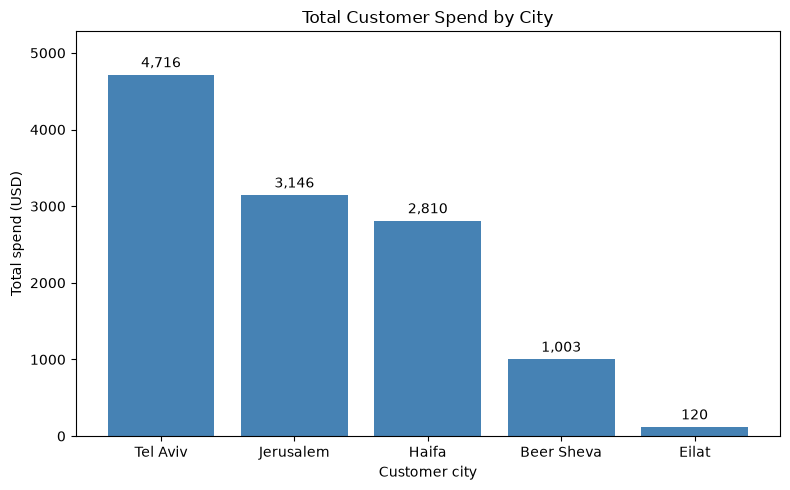

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(city_totals["city"], city_totals["city_total"], color="steelblue")
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in city_totals["city_total"]], padding=3)
ax.set_title("Total Customer Spend by City")
ax.set_xlabel("Customer city")
ax.set_ylabel("Total spend (USD)")
ax.set_ylim(0, city_totals["city_total"].max() * 1.12)
plt.tight_layout()
plt.show()

Tel Aviv leads with the highest total spend (about 4,716 USD across 3 customers), while Eilat, with a single customer, is the smallest.

## Self-check

This cell fails loudly if any query returns something unexpected.

In [10]:
assert len(big_spenders) == 4 and (big_spenders["total_spent"] > 1000).all()
assert len(like_result) == 5 and like_result["name"].str.contains("an", case=False).all()
assert pandas_match == sql_match
assert abs(city_totals["city_total"].sum() - pd.read_sql("SELECT SUM(total_spent) AS s FROM customers", con)["s"][0]) < 1e-6
print("All checks passed")

All checks passed


In [11]:
con.close()
print("Connection closed")

Connection closed
